# NO₂ in Chicago — replicating & extending Ma et al. (2020)

**Paper:** Ma, Y., Ma, B., Jiao, H., Zhang, Y., Xin, J., & Yu, Z. (2020). *An analysis of the effects of weather and air pollution on tropospheric ozone using a generalized additive model in Western China: Lanzhou, Gansu.* Atmospheric Environment 224, 117342.

**What they did:** a Gaussian GAM of pollutant concentration on smooth weather terms (temperature, wind speed, humidity) + long-term trend + season + weekend. Reported **adjusted R² = 0.594**, **deviance explained = 62.3%**, with **temperature** the dominant driver.


- **A** We adapted the GAM approach of Ma et al. (2020) and added drop-one predictor and predictor-group comparisons to assess their incremental contribution to model fit - their exact structure, response swapped to Chicago NO₂, same Gaussian family. Compare deviance explained and the dominant driver.
- **B** add every other observable driver I have (wind direction, precipitation, land use, hour-of-day). Rank which groups matter.

**NOTE** lagged NO₂ and PM₂.₅ (autoregressive forecasting), so they are deliberately excluded here. A prior spline test confirmed the weather–NO₂ relationships are nonlinear, which is why a GAM (not linear regression) is used.


A GAM estimates an outcome by combining contributions from several predictors. Ordinary linear regression assumes that each numerical predictor has a straight-line relationship with the outcome. A GAM can replace that straight line with a smooth curve. For example, the relationship between wind speed and NO2 may change across the wind-speed range. A smooth term allows the data to estimate that shape. The model penalizes unnecessary wiggliness so that a curve does not simply follow every fluctuation. Our model is additive: it combines separate predictor contributions. It does not explicitly include interactions, such as a temperature relationship that changes with humidity.


GAM equation: g(μ)=b0+f(x1)+f(x2)...+f(xp)

GAM equation in the model:
\begin{aligned}
\text{NO}_2 =\ & \beta_0 \\
&+ s_1(\text{temp}) + s_2(\text{wspd}) + s_3(\text{rhum}) + s_4(\text{wind\_u}) + s_5(\text{prcp}) \\
&+ s_6(\text{canopy}) + s_7(\text{impervious}) + s_8(\text{dist\_downtown}) \\
&+ s_9(\text{road\_expwy}) + s_{10}(\text{industrial}) \\
&+ f(\text{hour}) + f(\text{month}) + \beta_{w}\,\text{weekend} + \beta_{h}\,\text{is\_holiday} + \varepsilon
\end{aligned}

## 1. Setup, data, and feature sets

In [1]:
!pip install pygam

In [2]:
import pandas as pd, numpy as np, matplotlib.pyplot as plt
from pygam import LinearGAM, s, f

df = pd.read_parquet('master_hourly.parquet')
df = df[df['hours_since_obs'] == 0].copy()              # lag-validity / observation guard
df['weekend'] = (df['dow'] >= 5).astype(int)            # dow 0=Mon..6=Sun
df['ts']      = pd.to_datetime(df['ts_utc'])
df['trend']   = (df['ts'] - df['ts'].min()).dt.total_seconds() / 86400.0   # days since start

FACTORS = {'hour', 'month', 'weekend', 'is_holiday'}    # everything else is a smooth

# Part A: Ma et al.'s predictor set (response = no2)
repl_cols = ['temp', 'wspd_ms', 'rhum', 'trend', 'month', 'weekend']
# Part B: all my observable drivers except the lags
ext_cols  = ['temp','wspd_ms','rhum','wind_u','prcp',
             'canopy_pct','impervious_pct','dist_downtown_m','road_len_expwy_500','industrial_m2_500',
             'hour','month','weekend','is_holiday']

need = sorted(set(repl_cols) | set(ext_cols) | {'no2'})
dm   = df.dropna(subset=need).copy()
samp = dm.sample(n=min(150_000, len(dm)), random_state=0)   # sample for pyGAM fit speed
y = samp['no2'].astype(float).values
print(f"rows used: {len(samp):,}   response: no2 (ppb)")

def make_terms(cols, n_splines):
    t = None
    for i, c in enumerate(cols):
        term = f(i) if c in FACTORS else s(i, n_splines=n_splines)
        t = term if t is None else t + term
    return t

def dev_expl(g, X, yy):
    try:    return g.statistics_['pseudo_r2']['explained_deviance']
    except Exception:
        yh = g.predict(X); return 1 - np.sum((yy-yh)**2)/np.sum((yy-yy.mean())**2)

def adj_r2(g, X, yy):
    d = dev_expl(g, X, yy)
    try:    e = g.statistics_['edof']
    except Exception: e = np.nan
    return 1 - (1-d)*(len(yy)-1)/(len(yy)-e-1)

rows used: 150,000   response: no2 (ppb)


## 2. Part A — Replication of Ma et al.

Same structure: smooth(temperature, wind speed, humidity, trend) + factor(season, weekend). Gaussian family, like the paper.

In [3]:
from pygam import GammaGAM
Xr = samp[repl_cols].astype(float).values
gam_r = GammaGAM(make_terms(repl_cols, n_splines=10)).fit(Xr, y)
print(f"REPLICATION  deviance explained = {dev_expl(gam_r, Xr, y)*100:.1f}%   adjusted R^2 = {adj_r2(gam_r, Xr, y):.3f}")

REPLICATION  deviance explained = 30.5%   adjusted R^2 = 0.305


The baseline model explains 28.4% of the observed variation in the fitted sample. This means that its fitted values reduce squared error by approximately 28.4% compared with predicting the sample mean for every observation.

### 2a. Which weather driver dominates? (drop-one)

In [4]:
base = dev_expl(gam_r, Xr, y)
weather = {0:'temp', 1:'wspd_ms', 2:'rhum'}
rows = []
for drop, name in weather.items():
    keep = [i for i in range(len(repl_cols)) if i != drop]
    g = GammaGAM(make_terms([repl_cols[i] for i in keep], n_splines=10)).fit(Xr[:, keep], y)
    rows.append({'dropped': name,
                 'dev_without_%': round(dev_expl(g, Xr[:, keep], y)*100, 1),
                 'drop_pts': round((base - dev_expl(g, Xr[:, keep], y))*100, 2)})
print(f"full: {base*100:.1f}%")
print(pd.DataFrame(rows).sort_values('drop_pts', ascending=False).to_string(index=False))
print("Largest drop = most important (Ma et al.: temperature; here: wind).")

full: 30.5%
dropped  dev_without_%  drop_pts
wspd_ms           12.8     17.70
   rhum           28.8      1.67
   temp           29.4      1.06
Largest drop = most important (Ma et al.: temperature; here: wind).


Wind speed provides the largest incremental contribution among the three weather variables tested in this baseline specification. Removing it reduces explained deviance from approximately 28.4% to 11.8%.This does not mean wind causes 16.53% of pollution. It means the model fits the observations substantially less well when wind speed is unavailable.

Smaller decreases for temperature and humidity do not mean those variables have no association with NO2. Some of their information may overlap with month, elapsed time, or other predictors.



### 2b. Compare to the paper

In [5]:
print(pd.DataFrame({
    'metric': ['adjusted R^2', 'deviance explained %', 'dominant driver'],
    'Ma et al. 2020 (O3, Lanzhou)': ['0.594', '62.3', 'temperature'],
    'This study (NO2, Chicago)':    [f'{adj_r2(gam_r,Xr,y):.3f}', f'{dev_expl(gam_r,Xr,y)*100:.1f}', 'wind speed'],
}).to_string(index=False))

              metric Ma et al. 2020 (O3, Lanzhou) This study (NO2, Chicago)
        adjusted R^2                        0.594                     0.305
deviance explained %                         62.3                      30.5
     dominant driver                  temperature                wind speed


## Part B: all observable drivers (no lags)

Add wind direction (`wind_u`), precipitation, the five land-use variables, and hour-of-day. Still one explanatory Gaussian GAM.

In [6]:
Xe = samp[ext_cols].astype(float).values
gam_e = GammaGAM(make_terms(ext_cols, n_splines=8)).fit(Xe, y)
print(f"EXTENDED  deviance explained = {dev_expl(gam_e, Xe, y)*100:.1f}%   adjusted R^2 = {adj_r2(gam_e, Xe, y):.3f}")
print(pd.DataFrame({
    'model': ['Replication (weather+season+weekend)', 'Extended (+wind_u, precip, land use, hour)'],
    'deviance explained %': [f'{dev_expl(gam_r,Xr,y)*100:.1f}', f'{dev_expl(gam_e,Xe,y)*100:.1f}'],
}).to_string(index=False))

EXTENDED  deviance explained = 35.7%   adjusted R^2 = 0.356
                                     model deviance explained %
      Replication (weather+season+weekend)                 30.5
Extended (+wind_u, precip, land use, hour)                 35.7


### 3a. Which *group* of drivers matters most? (group drop-one)

In [7]:
groups = {'weather (temp,wind,wind_u,rhum,prcp)': [0,1,2,3,4],
          'location (land use)':                  [5,6,7,8,9],
          'time (hour,month,weekend,holiday)':    [10,11,12,13]}
base_e = dev_expl(gam_e, Xe, y)
rows = []
for name, drop in groups.items():
    keep = [i for i in range(len(ext_cols)) if i not in drop]
    g = GammaGAM(make_terms([ext_cols[i] for i in keep], n_splines=8)).fit(Xe[:, keep], y)
    d = dev_expl(g, Xe[:, keep], y)
    rows.append({'group_dropped': name, 'dev_without_%': round(d*100,1), 'drop_pts': round((base_e-d)*100,2)})
print(f"full: {base_e*100:.1f}%")
print(pd.DataFrame(rows).sort_values('drop_pts', ascending=False).to_string(index=False))


full: 35.7%
                       group_dropped  dev_without_%  drop_pts
weather (temp,wind,wind_u,rhum,prcp)           15.2     20.50
   time (hour,month,weekend,holiday)           28.1      7.58
                 location (land use)           33.3      2.35


## 4. Effect curves (the nonlinear shapes)

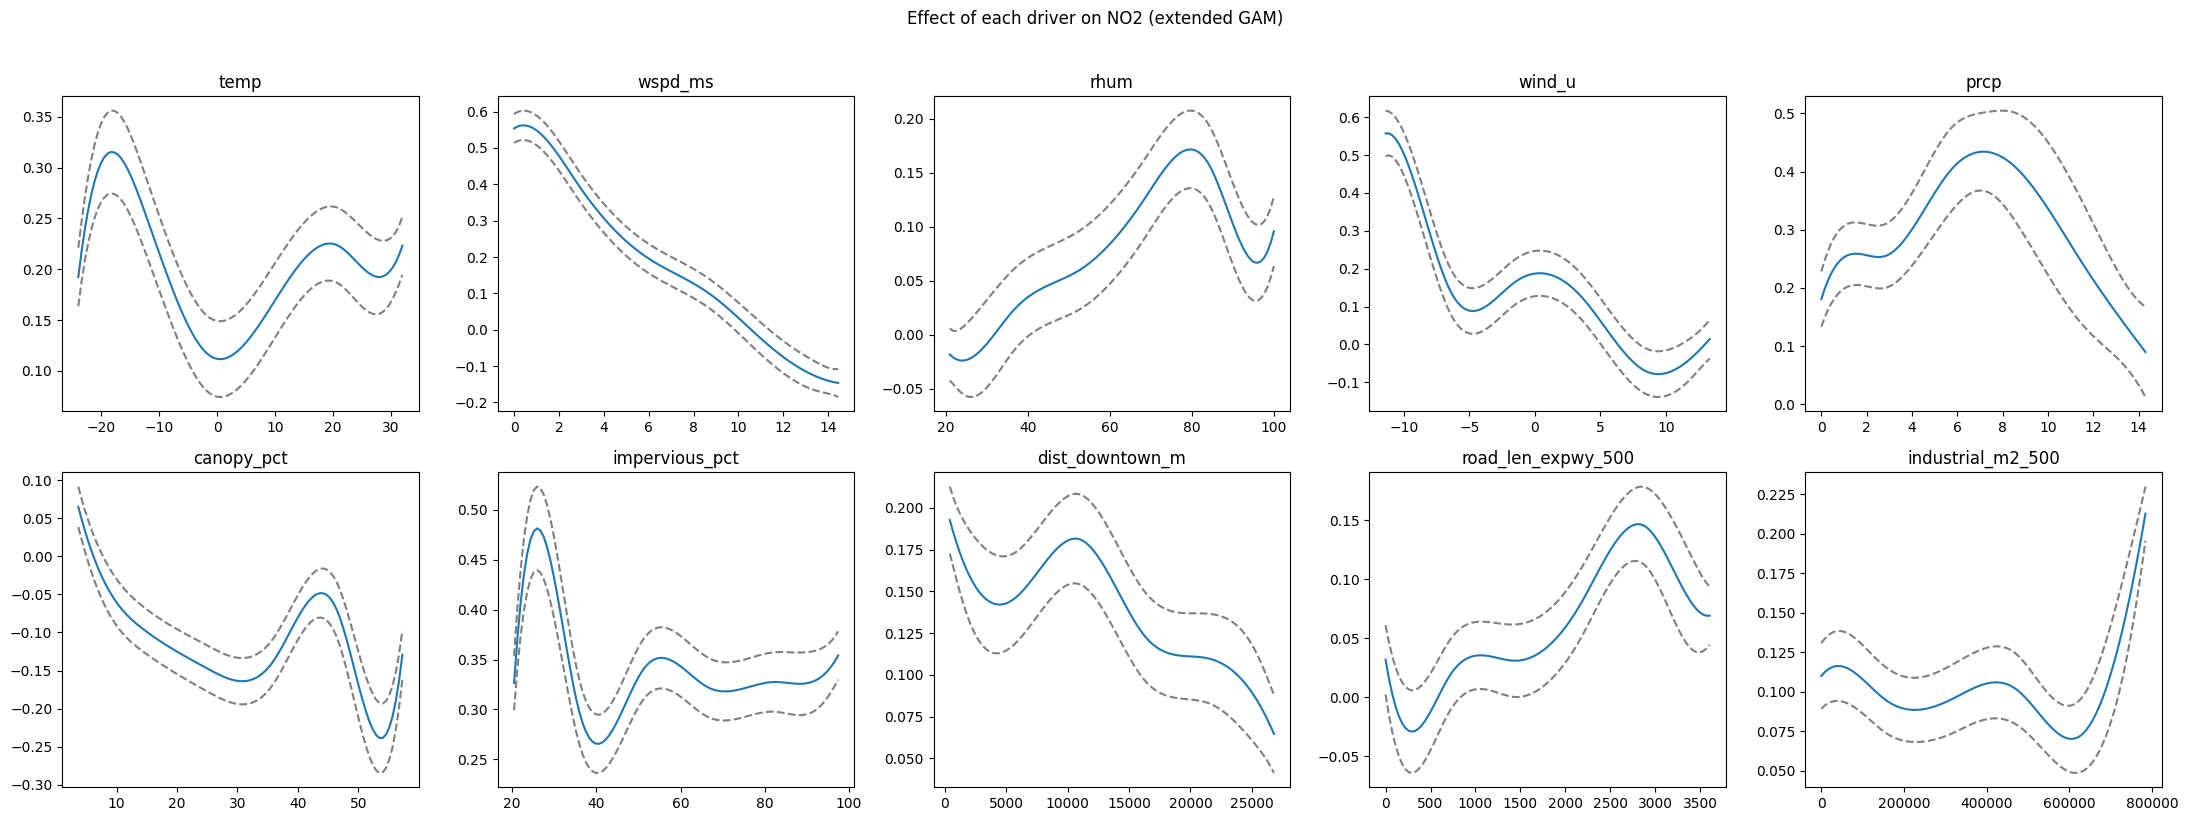

In [8]:
cont = ext_cols[:10]                      # the 10 continuous drivers
rep = np.median(Xe, axis=0)
rep[10], rep[11], rep[12], rep[13] = 12, 6, 0, 0   # hold hour/month/weekend/holiday at valid levels
fig, axes = plt.subplots(2, 5, figsize=(22, 8))
for i, ax in enumerate(axes.ravel()):
    grid = np.linspace(Xe[:, i].min(), Xe[:, i].max(), 100)
    xx = np.tile(rep, (100, 1)); xx[:, i] = grid
    pdep, ci = gam_e.partial_dependence(term=i, X=xx, width=0.95)
    ax.plot(grid, pdep); ax.plot(grid, ci, ls='--', c='grey')
    ax.set_title(cont[i])
fig.suptitle('Effect of each driver on NO2 (extended GAM)', y=1.02)
plt.tight_layout(); plt.savefig('no2_gam_curves.png', dpi=130, bbox_inches='tight'); plt.show()

The horizontal axis shows the predictor value.

The vertical axis shows that predictor’s fitted contribution to NO2, in ppb, relative to the model’s centering convention.

An upward curve means the model associates larger predictor values with larger contributions.

A downward curve means the opposite.

A bend suggests the association changes across the predictor’s range.

A nearly flat curve suggests little fitted change over that range.

A negative contribution does not mean negative NO2. It means this term lowers the prediction relative to other parts of the model.

The dashed lines are default model-based uncertainty intervals. They do not account for the full dependence between repeated sensor observations and shared pollution episodes.



### Does allowing a predictor’s relationship with NO2 to curve improve model fit compared with forcing that relationship to be a straight line

In [9]:
import pandas as pd, numpy as np
import statsmodels.formula.api as smf
from statsmodels.stats.anova import anova_lm

# uses df already loaded in the notebook; rebuilds its own model frame
d = df[df['hours_since_obs'] == 0].copy()
d['weekend'] = (d['dow'] >= 5).astype(int)

cont = ['temp','wspd_ms','rhum','wind_u','prcp',
        'canopy_pct','impervious_pct','dist_downtown_m',
        'road_len_expwy_500','industrial_m2_500']
cats = ['C(hour)','weekend','is_holiday','C(month)']
need = cont + ['hour','weekend','is_holiday','month','no2']
dm = d.dropna(subset=need).copy()

# model with every driver as a STRAIGHT line (baseline)
lin_terms = cont + cats
m_lin = smf.ols('no2 ~ ' + ' + '.join(lin_terms), data=dm).fit()

# swap ONE driver at a time to a bendy spline, see if the fit improves
rows = []
for v in cont:
    terms = [f'cr({v}, df=4)' if t == v else t for t in lin_terms]
    m_alt = smf.ols('no2 ~ ' + ' + '.join(terms), data=dm).fit()
    aov = anova_lm(m_lin, m_alt)
    rows.append({'variable': v,
                 'F': round(aov['F'][1], 1),
                 'p': aov['Pr(>F)'][1],
                 'dAIC': round(m_alt.aic - m_lin.aic, 1),      # more negative = curve helps more
                 'dAdjR2': round(m_alt.rsquared_adj - m_lin.rsquared_adj, 4)})
print(pd.DataFrame(rows).sort_values('dAIC').to_string(index=False))

# overall: all drivers straight vs all drivers bendy
m_spl = smf.ols('no2 ~ ' + ' + '.join([f'cr({v}, df=4)' for v in cont] + cats), data=dm).fit()
print(f"\nstraight lines : adj R2 = {m_lin.rsquared_adj:.4f}   AIC = {m_lin.aic:.0f}")
print(f"bendy splines  : adj R2 = {m_spl.rsquared_adj:.4f}   AIC = {m_spl.aic:.0f}")

/tmp/ipykernel_3557/639346070.py:24: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  m_alt = smf.ols('no2 ~ ' + ' + '.join(terms), data=dm).fit()
/tmp/ipykernel_3557/639346070.py:24: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  m_alt = smf.ols('no2 ~ ' + ' + '.join(terms), data=dm).fit()
/tmp/ipykernel_3557/639346070.py:24: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  m_alt = smf.ols('no2 ~ ' + ' + '.join(terms), data=dm).fit()
/tmp/ipykernel_3557/639346070.py:24: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  m_alt = smf.ols('no2 ~ ' + ' + '.join(terms), data=dm).fit()
/tmp/ipykernel_3557/639346070.py:24: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  m_alt = smf

          variable      F             p     dAIC  dAdjR2
              temp 5901.3  0.000000e+00 -11741.7  0.0069
           wspd_ms 3407.0  0.000000e+00  -6791.0  0.0040
              rhum 3159.9  0.000000e+00  -6299.5  0.0037
            wind_u 2964.4  0.000000e+00  -5910.4  0.0035
        canopy_pct 2542.1  0.000000e+00  -5069.8  0.0030
   dist_downtown_m  493.7 4.792449e-215   -983.0  0.0006
 industrial_m2_500  449.0 1.155855e-195   -893.8  0.0005
              prcp  331.8 8.562329e-145   -659.5  0.0004
road_len_expwy_500  177.8  6.035055e-78   -351.6  0.0002
    impervious_pct  159.7  4.413403e-70   -315.4  0.0002


/tmp/ipykernel_3557/639346070.py:34: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  m_spl = smf.ols('no2 ~ ' + ' + '.join([f'cr({v}, df=4)' for v in cont] + cats), data=dm).fit()



straight lines : adj R2 = 0.2833   AIC = 7390179
bendy splines  : adj R2 = 0.3102   AIC = 7344148
